# 📊 Understanding the Performance Metrics, Cross-Validation, and Generalization

This notebook trains and compares several classifiers on a diabetes dataset.
Before looking at the results, here is a guide to **every metric** you will see,
so you know exactly what is being measured and why.

---

## 1. The Confusion Matrix

Almost every metric below is derived from the **confusion matrix**, which
cross-tabulates the predicted labels against the true labels:

|                  | Predicted **Negative** | Predicted **Positive** |
|------------------|------------------------|------------------------|
| **Actual Negative** | True Negative (TN)  | False Positive (FP) — *Type I error* |
| **Actual Positive** | False Negative (FN) — *Type II error* | True Positive (TP) |

In a **medical screening** context (diabetes), the "Positive" class is usually
*"patient has diabetes"*. Missing a sick patient (FN) is typically considered
**more costly** than a false alarm (FP). Keep this in mind when reading the metrics.

---

## 2. Classification Metrics

### Accuracy
$$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
The overall fraction of correct predictions. **Misleading when classes are
imbalanced** (e.g., if 90 % of patients are healthy, a model that always predicts
"healthy" gets 90 % accuracy but is useless).

### Sensitivity (Recall, True Positive Rate)
$$\text{Sensitivity} = \frac{TP}{TP + FN}$$
Of all the **actually sick** patients, how many did we catch? High sensitivity
means few missed diagnoses (few false negatives).

### Specificity (True Negative Rate)
$$\text{Specificity} = \frac{TN}{TN + FP}$$
Of all the **actually healthy** patients, how many did we correctly clear? High
specificity means few false alarms (few false positives).

> ⚖️ **Sensitivity vs. Specificity trade-off:** Lowering the decision threshold
> increases sensitivity but decreases specificity, and vice versa. This is why
> we also look at the ROC curve.

### Precision (Positive Predictive Value)
$$\text{Precision} = \frac{TP}{TP + FP}$$
When the model says *"diabetic"*, how often is it right? Important when a
positive prediction triggers an expensive or invasive follow-up test.

### F1-Score
$$F_1 = 2 \cdot \frac{\text{Precision} \cdot \text{Recall}}{\text{Precision} + \text{Recall}}$$
The **harmonic mean** of precision and recall. Useful as a single number when
classes are imbalanced, since it penalizes extreme imbalances between precision
and recall.

### ROC Curve and AUC
The **Receiver Operating Characteristic (ROC)** curve plots
**Sensitivity (TPR)** against **1 − Specificity (FPR)** for *every possible
decision threshold*. The **Area Under the Curve (AUC)** summarizes it:

| AUC value | Interpretation |
|-----------|----------------|
| 0.5       | Random guessing (useless) |
| 0.7–0.8   | Acceptable |
| 0.8–0.9   | Good |
| > 0.9     | Excellent |

AUC has a neat probabilistic meaning: *it is the probability that the model
ranks a randomly chosen positive patient above a randomly chosen negative
patient.* It is **threshold-independent**, which makes it great for comparing
models fairly.

---

## 3. Cross-Validation (CV)

A single train/test split gives a noisy estimate: you might get lucky or unlucky
with how the data was divided. **k-Fold Cross-Validation** solves this:

1. Split the training data into **k folds** (here **k = 5**).
2. Train on **k − 1** folds and validate on the remaining fold.
3. Repeat **k times**, each time holding out a different fold.
4. **Average** the k validation scores → a more stable and reliable estimate.

> 🔒 **Why we use `Pipeline` inside CV:** Scaling (e.g., `StandardScaler`) must
> be fitted **only on the training folds**. If we scaled the whole dataset first,
> information from the validation fold would "leak" into training and inflate the
> scores. Wrapping the scaler and the classifier in a `Pipeline` guarantees that
> every fold is preprocessed independently — this is called **avoiding data leakage**.

### Cross-Validation Error
The **CV error** is simply:
$$\text{CV Error} = 1 - \text{CV Score}$$
For accuracy, this is the **misclassification rate** averaged over the k folds.
It estimates **how well the model will generalize to unseen data** — a low CV
error means the model is expected to perform well on new patients, not just on
the data it memorized.

Note that the CV score is computed on data the model **did not see during
training in that fold**, so it is an *out-of-sample* estimate — unlike the
training score, which is *in-sample*.

---

## 4. Generalization Analysis (Learning Curves)

The learning curve plots **training error** and **cross-validation error** as a
function of the **number of training samples** used.

Why plot **error** instead of accuracy? Because error curves are easier to read:

- **The y-axis is the misclassification rate.** *Lower is better.*
- The **gap** between the two curves is the **generalization gap**
  (= CV error − training error).

How to interpret the shapes:

| Pattern | Diagnosis |
|---------|-----------|
| Training error very low, CV error high, **large gap** | **Overfitting** (high variance). The model memorizes training data but does not generalize. |
| Both errors high and close together | **Underfitting** (high bias). The model is too simple. |
| Both errors converge to a low value as data grows | **Good fit.** More data helps. |
| CV error still decreasing at the right edge | **More data would likely help.** |
| Training error rising toward CV error | Model is beginning to underfit due to too much data for its capacity. |

The goal is to find a model where:
1. The **CV error is low** (good generalization), and
2. The **gap is small** (the model is not just memorizing).

If the gap is large, remedies include: more data, stronger regularization,
simpler models, or early stopping. If both errors are high, remedies include:
more complex models, better features, or longer training.

Loading dataset...
Dataset shape: (767, 8)
Class distribution:
1
0    0.65189
1    0.34811
Name: proportion, dtype: float64

Running Cross-Validation...
Training Logistic Regression...
Training Random Forest...
Training Naive Bayes...
Training K-Nearest Neighbors...
Training SVM (RBF)...
Training MLP (Neural Net)...
Training XGBoost...

=== Cross-Validation Results ===
              Model  Accuracy  Sensitivity  Specificity  Precision       F1      AUC
          SVM (RBF)  0.769919     0.590808       0.8650   0.702710 0.639598 0.835208
      Random Forest  0.776529     0.610188       0.8650   0.710313 0.654952 0.834451
Logistic Regression  0.786232     0.586489       0.8925   0.751112 0.656017 0.834099
        Naive Bayes  0.763428     0.609856       0.8450   0.690006 0.640946 0.824737
            XGBoost  0.760256     0.596346       0.8475   0.675756 0.632546 0.819952
K-Nearest Neighbors  0.714514     0.506866       0.8250   0.608989 0.550112 0.772442
   MLP (Neural Net)  0.717793    

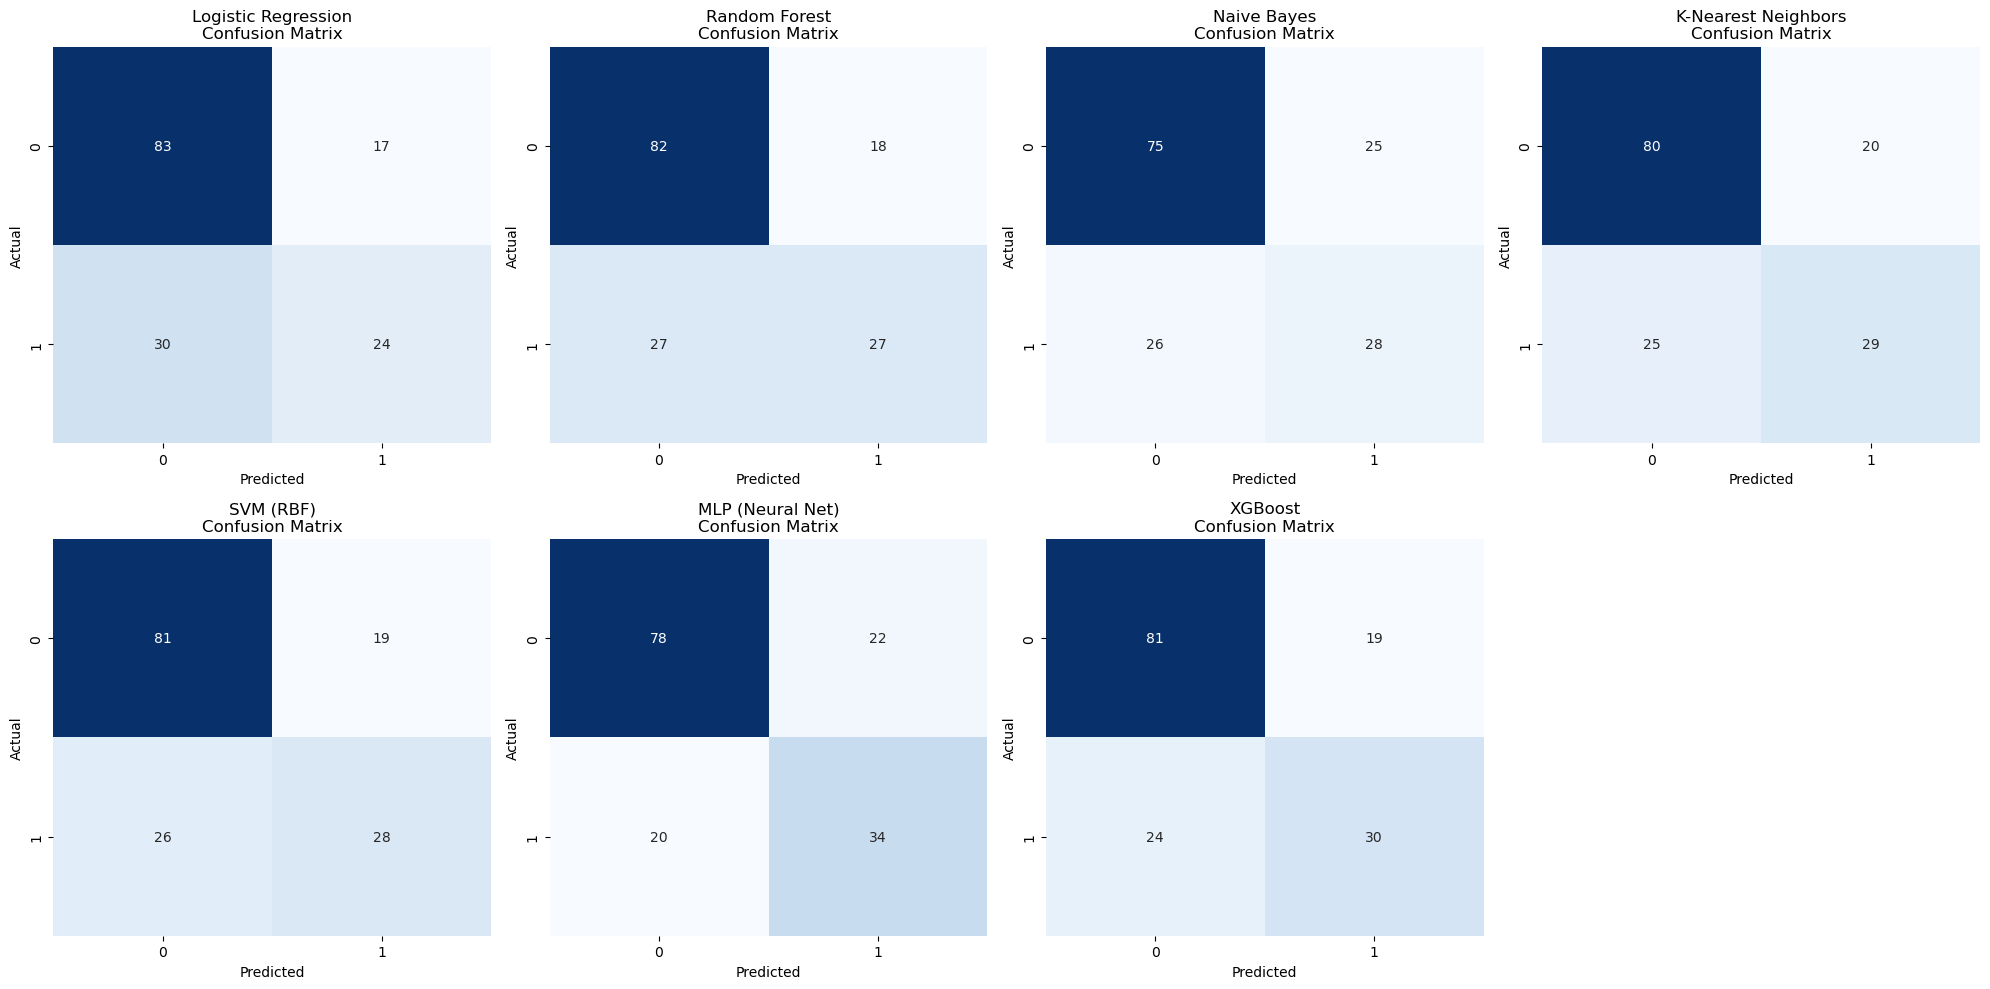

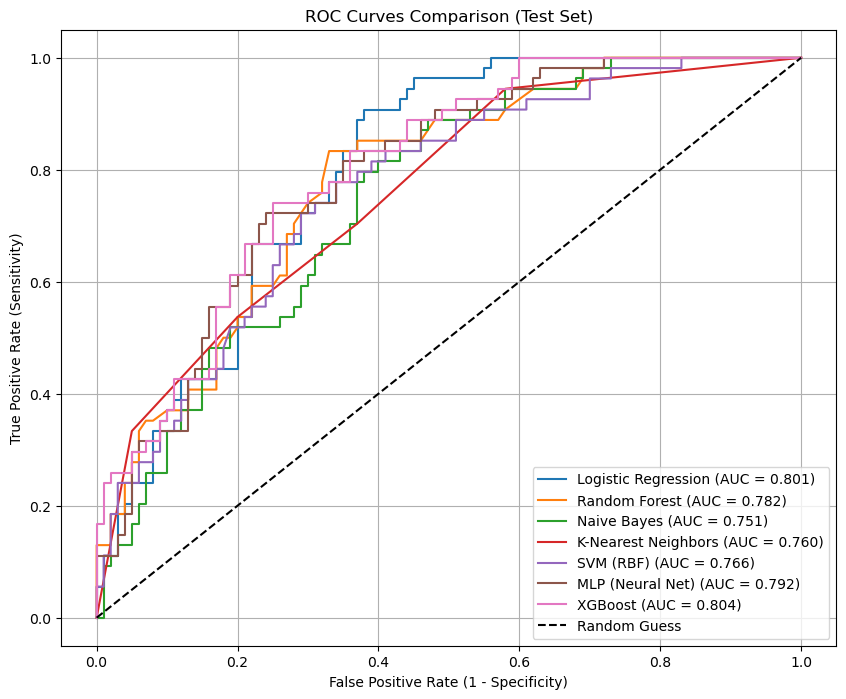


Generating Error Learning Curves...
Logistic Regression:
   Training error = 0.204 | CV error = 0.214 | Generalization gap = +0.010
Random Forest:
   Training error = 0.000 | CV error = 0.227 | Generalization gap = +0.227
Naive Bayes:
   Training error = 0.218 | CV error = 0.237 | Generalization gap = +0.019
K-Nearest Neighbors:
   Training error = 0.179 | CV error = 0.285 | Generalization gap = +0.106
SVM (RBF):
   Training error = 0.153 | CV error = 0.230 | Generalization gap = +0.077
MLP (Neural Net):
   Training error = 0.000 | CV error = 0.272 | Generalization gap = +0.272
XGBoost:
   Training error = 0.037 | CV error = 0.241 | Generalization gap = +0.205


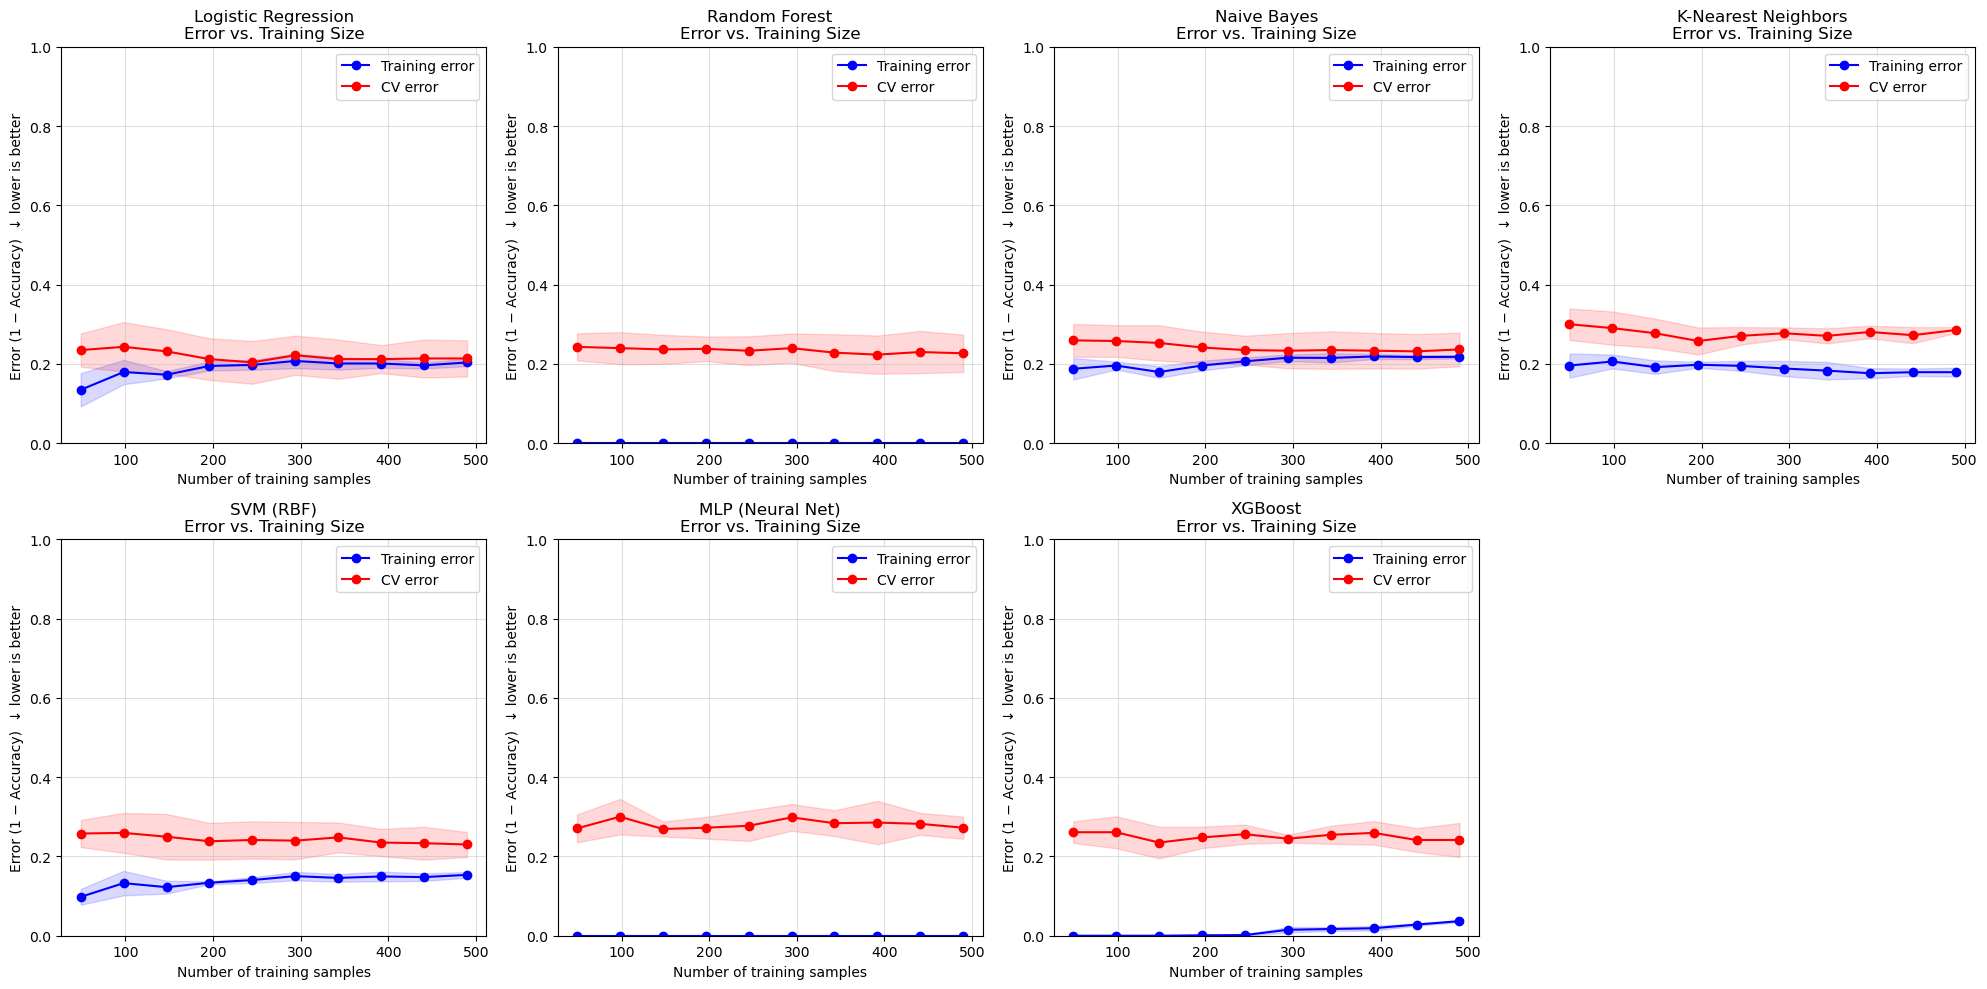


Interpretation guide:
  - Large positive gap (CV error >> training error)  -> OVERFITTING
  - Both errors high and close together              -> UNDERFITTING
  - Both low and converging                          -> GOOD FIT
  - CV error still dropping at the right edge        -> MORE DATA MAY HELP

Analysis Complete.


In [1]:
# ==============================================================================
# DIABETES CLASSIFICATION BENCHMARKING PIPELINE
# ==============================================================================
# Description: This script compares multiple classifiers on the Pima Indians
#              Diabetes dataset. It evaluates performance using confusion
#              matrices, sensitivity, specificity, AUC, and analyzes
#              generalization through learning curves.
# ==============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn Core
from sklearn.model_selection import train_test_split, StratifiedKFold, learning_curve, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (confusion_matrix, classification_report, 
                             roc_auc_score, roc_curve, accuracy_score, 
                             recall_score, precision_score, f1_score,
                             make_scorer)

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# Optional: XGBoost (install via pip/conda if not available)
try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("XGBoost not installed. Skipping XGBClassifier.")

# ==============================================================================
# 1. DATA LOADING & PREPROCESSING
# ==============================================================================
print("Loading dataset...")
# Assuming 'diabetes.csv' is in the same directory. 
# Download from: https://www.kaggle.com/datasets/uciml/pima-indians-diabetes-database
try:
    df = pd.read_csv('diabetes.csv')
except FileNotFoundError:
    print("Error: 'diabetes.csv' not found. Please download the Pima Indians Diabetes Database.")
    # Create a dummy dataset for demonstration if file is missing
    from sklearn.datasets import make_classification
    X_dummy, y_dummy = make_classification(n_samples=768, n_features=8, random_state=42)
    df = pd.DataFrame(X_dummy, columns=[f'Feature_{i}' for i in range(8)])
    df['Outcome'] = y_dummy

# Basic cleaning (Pima dataset often has zeros in columns where they are physiologically impossible)
# For simplicity, we will just replace zeros with NaN and impute with median for columns like Glucose, BP, etc.
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
if all(col in df.columns for col in cols_with_zeros):
    df[cols_with_zeros] = df[cols_with_zeros].replace(0, np.nan)
    df.fillna(df.median(), inplace=True)

# Separate features and target
# Assuming the target column is named 'Outcome' (standard for Pima)
target_col = 'Outcome'
if target_col not in df.columns:
    # Fallback for dummy data
    target_col = df.columns[-1]

X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Dataset shape: {X.shape}")
print(f"Class distribution:\n{y.value_counts(normalize=True)}")

# Train-Test Split (Stratified to maintain class balance)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# ==============================================================================
# 2. DEFINE CLASSIFIERS & PIPELINES
# ==============================================================================
# We use Pipelines to ensure scaling is applied correctly within CV folds for scale-sensitive models.
# Note: Tree-based models (RF, XGB) do not strictly need scaling, but it doesn't hurt.

classifiers = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1),
    'Naive Bayes': GaussianNB(),
    'K-Nearest Neighbors': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ]),
    'SVM (RBF)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(kernel='rbf', probability=True, random_state=42))
    ]),
    'MLP (Neural Net)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=1000, random_state=42))
    ])
}

if HAS_XGB:
    classifiers['XGBoost'] = XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=4, 
        use_label_encoder=False, eval_metric='logloss', random_state=42
    )

# ==============================================================================
# 3. EVALUATION METRICS & CROSS-VALIDATION
# ==============================================================================
# Define custom scorers for metrics not built-in by default
def specificity_score(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return tn / (tn + fp)

scoring = {
    'accuracy': 'accuracy',
    'sensitivity': 'recall', # Recall is Sensitivity
    'specificity': make_scorer(specificity_score),
    'precision': 'precision',
    'f1': 'f1',
    'auc': 'roc_auc'
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

results = []
print("\nRunning Cross-Validation...")
for name, model in classifiers.items():
    print(f"Training {name}...")
    cv_results = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    
    # Store mean results
    results.append({
        'Model': name,
        'Accuracy': cv_results['test_accuracy'].mean(),
        'Sensitivity': cv_results['test_sensitivity'].mean(),
        'Specificity': cv_results['test_specificity'].mean(),
        'Precision': cv_results['test_precision'].mean(),
        'F1': cv_results['test_f1'].mean(),
        'AUC': cv_results['test_auc'].mean()
    })

results_df = pd.DataFrame(results).sort_values(by='AUC', ascending=False)
print("\n=== Cross-Validation Results ===")
print(results_df.to_string(index=False))

# ==============================================================================
# 4. TEST SET EVALUATION & CONFUSION MATRICES
# ==============================================================================
# Train final models on full training set and evaluate on test set
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(classifiers.items()):
    if i >= len(axes): break
    
    # Fit
    model.fit(X_train, y_train)
    
    # Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1] if hasattr(model, "predict_proba") else None
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i], cbar=False)
    axes[i].set_title(f'{name}\nConfusion Matrix')
    axes[i].set_xlabel('Predicted')
    axes[i].set_ylabel('Actual')
    
    # Print Report
    print(f"\n--- {name} (Test Set) ---")
    print(classification_report(y_test, y_pred, target_names=['Non-Diabetic', 'Diabetic']))
    
    # Generalization Gap (Train Accuracy - Test Accuracy)
    train_acc = model.score(X_train, y_train)
    test_acc = model.score(X_test, y_test)
    print(f"Training Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f} | Gap: {train_acc - test_acc:.4f}")

# Hide unused subplots
for j in range(i + 1, len(axes)):
    axes[j].axis('off')
plt.tight_layout()
plt.show()

# ==============================================================================
# 5. ROC CURVES COMPARISON
# ==============================================================================
plt.figure(figsize=(10, 8))
for name, model in classifiers.items():
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_test)[:, 1]
        fpr, tpr, _ = roc_curve(y_test, y_prob)
        auc_score = roc_auc_score(y_test, y_prob)
        plt.plot(fpr, tpr, label=f'{name} (AUC = {auc_score:.3f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Guess')
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity)')
plt.title('ROC Curves Comparison (Test Set)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

# ==============================================================================
# 6. GENERALIZATION ANALYSIS — ERROR vs. NUMBER OF TRAINING SAMPLES
# ==============================================================================
# We plot ERROR (1 - accuracy) instead of accuracy, so LOWER IS BETTER.
# The gap between the training-error curve and the CV-error curve is the
# generalization gap: a large gap signals overfitting.

print("\nGenerating Error Learning Curves...")
fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

# Fractions of the training set to use
train_sizes = np.linspace(0.1, 1.0, 10)

for i, (name, model) in enumerate(classifiers.items()):
    if i >= len(axes):
        break

    # learning_curve returns ACCURACY scores; we convert to ERROR below
    train_sizes_abs, train_scores, val_scores = learning_curve(
        model, X_train, y_train, train_sizes=train_sizes, cv=cv,
        scoring='accuracy', n_jobs=-1, random_state=42
    )

    # Convert accuracy -> error  (error = 1 - accuracy)
    train_err = 1.0 - train_scores
    val_err   = 1.0 - val_scores

    train_err_mean = np.mean(train_err, axis=1)
    train_err_std  = np.std(train_err, axis=1)
    val_err_mean   = np.mean(val_err, axis=1)
    val_err_std    = np.std(val_err, axis=1)

    # Plot training error (blue)
    axes[i].plot(train_sizes_abs, train_err_mean, 'o-', color='blue',
                 label='Training error')
    axes[i].fill_between(train_sizes_abs,
                         train_err_mean - train_err_std,
                         train_err_mean + train_err_std,
                         alpha=0.15, color='blue')

    # Plot cross-validation error (red)
    axes[i].plot(train_sizes_abs, val_err_mean, 'o-', color='red',
                 label='CV error')
    axes[i].fill_between(train_sizes_abs,
                         val_err_mean - val_err_std,
                         val_err_mean + val_err_std,
                         alpha=0.15, color='red')

    axes[i].set_title(f'{name}\nError vs. Training Size')
    axes[i].set_xlabel('Number of training samples')
    axes[i].set_ylabel('Error (1 − Accuracy)  ↓ lower is better')
    axes[i].set_ylim(0, 1)
    axes[i].legend(loc='best')
    axes[i].grid(True, alpha=0.4)

    # Diagnostic printout
    final_train_err = train_err_mean[-1]
    final_val_err   = val_err_mean[-1]
    gap = final_val_err - final_train_err
    print(f"{name}:")
    print(f"   Training error = {final_train_err:.3f} | "
          f"CV error = {final_val_err:.3f} | "
          f"Generalization gap = {gap:+.3f}")

for j in range(i + 1, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

print("\nInterpretation guide:")
print("  - Large positive gap (CV error >> training error)  -> OVERFITTING")
print("  - Both errors high and close together              -> UNDERFITTING")
print("  - Both low and converging                          -> GOOD FIT")
print("  - CV error still dropping at the right edge        -> MORE DATA MAY HELP")
print("\nAnalysis Complete.")